# PaperLu3 — Benchmarking ten feature-selection algorithms for circulating miRNA lung-cancer biomarkers: accuracy, stability, transportability and biological concordance

**Design.** Ten feature-selection (FS) algorithms spanning filter, embedded and wrapper families, plus a Borda consensus and
a random-selection negative control, are applied in three discovery regimes:
* **D1** E-MTAB-8026 — large whole-blood cohort (Agilent), n = 1570
* **D2** GSE137140 — large serum cohort (3D-Gene), n = 3744 (near-ceiling separability; stress test)
* **D3** GSE61741 — small whole-blood cohort (Geniom), n = 167 (small-n regime)

Each FS method produces a full ranking over the 816 miRNAs measured in all cohorts; top-k subsets (k = 5, 10, 20) feed two fixed
downstream classifiers (L2-logistic regression and random forest) so that differences are attributable to the selector.
Evaluation axes: (A) nested-CV discrimination, (B) selection stability (Kuncheva index), (C) overlap-aware external
transportability, (D) biological concordance (direction/significance in independent cohorts and TCGA tissue), (E) redundancy,
(F) capture of the global (sample-mean) component, (G) runtime; then a multi-criteria ranking.

In [1]:
import os, sys, json, time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from functools import reduce
from scipy import stats
from scipy.cluster.hierarchy import linkage, leaves_list
sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))
from lung_mirna_utils import *
from fs_methods import METHODS, METHOD_FAMILY, borda, fs_boruta, fs_stability
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.base import clone

set_plot_style()
FIG, TAB = "figures", "tables"
os.makedirs(FIG, exist_ok=True); os.makedirs(TAB, exist_ok=True)
RS = 42
KS = [5, 10, 20]
CLFS = ["LR", "RF"]
DISC = {"D1": "E-MTAB-8026", "D2": "GSE137140", "D3": "GSE61741"}
N_SUB = 10            # additional 80% subsamples for stability (plus 5 CV training folds = 15 rankings)
N_RANDOM = 20         # random-selection draws (negative control)
RESULTS = {}
t0 = time.time()
MNAMES = list(METHODS.keys())
ALL_M = MNAMES + ["Borda", "Random"]
MCOL = dict(zip(ALL_M, plt.cm.tab20(np.linspace(0, 1, len(ALL_M)))))

def savefig(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{FIG}/{name}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)

## 1. Data, common universe, overlap map

In [2]:
alias = load_alias_table(); NAMES = mimat_names(alias)
data = load_all()
U = sorted(reduce(lambda a, b: a & b, [set(X.columns) for X, _ in data.values()]))
P = len(U)
pair_tab, clusters = overlap_audit(data)
Xt, yt, ctp = load_tcga()
TC = anova_table(Xt[[f for f in U if f in Xt.columns]], yt).set_index("feature")
FULL_ANOVA = {c: anova_table(data[c][0][U], data[c][1]).set_index("feature") for c in COHORT_ORDER}
ROWMEAN = {c: data[c][0].mean(axis=1).values for c in COHORT_ORDER}
print("Universe:", P, "miRNAs")
T1 = pd.DataFrame([dict(Regime=k, Cohort=v, Specimen=COHORTS[v]["specimen"], Platform=COHORTS[v]["platform"],
                        N=len(data[v][1]), Cases=int(data[v][1].sum()), Controls=int((data[v][1] == 0).sum()))
                   for k, v in DISC.items()])
T1.to_csv(f"{TAB}/Table1_discovery_regimes.csv", index=False)
T2 = pd.DataFrame([dict(Method=m, Family=METHOD_FAMILY[m]) for m in MNAMES] +
                  [dict(Method="Borda", Family="Ensemble (rank aggregation of the 10 methods)"),
                   dict(Method="Random", Family="Negative control (random k-subsets)")])
T2["Key settings"] = [
    "f_classif; rank by F", "k-NN estimator (k=5); rank by MI", "relevance = F, redundancy = mean |r|, quotient; greedy to 60",
    "10 nearest hits/misses, ≤800 sampled instances, min-max scaled", "L1-logistic path (18 C values); rank by entry order",
    "50 half-subsamples, randomised L1 (weakness 0.5), C tuned to ≈25 features; rank by frequency",
    "500 trees, balanced; mean decrease in impurity", "300 trees, depth 4, eta 0.05; total gain",
    "linear SVM (C=0.05), 10% elimination per step", "30 iterations, ExtraTrees(150, depth 7) vs shadow features; binomial test",
    "Borda count over the 10 full rankings", "20 random draws"]
T2.to_csv(f"{TAB}/Table2_methods.csv", index=False)
T2

Universe: 816 miRNAs


,Method,Family,Key settings
0,ANOVA,Filter (univariate),f_classif; rank by F
1,MutualInfo,Filter (univariate),k-NN estimator (k=5); rank by MI
2,mRMR,Filter (multivariate),"relevance = F, redundancy = mean |r|, quotient..."
3,ReliefF,Filter (multivariate),"10 nearest hits/misses, ≤800 sampled instances..."
4,LASSO,Embedded (sparse linear),L1-logistic path (18 C values); rank by entry ...
5,StabilitySel,Embedded (resampled sparse),"50 half-subsamples, randomised L1 (weakness 0...."
6,RF-Imp,Embedded (tree ensemble),"500 trees, balanced; mean decrease in impurity"
7,XGB-Gain,Embedded (boosting),"300 trees, depth 4, eta 0.05; total gain"
8,SVM-RFE,Wrapper (linear SVM),"linear SVM (C=0.05), 10% elimination per step"
9,Boruta,Wrapper (all-relevant),"30 iterations, ExtraTrees(150, depth 7) vs sha..."


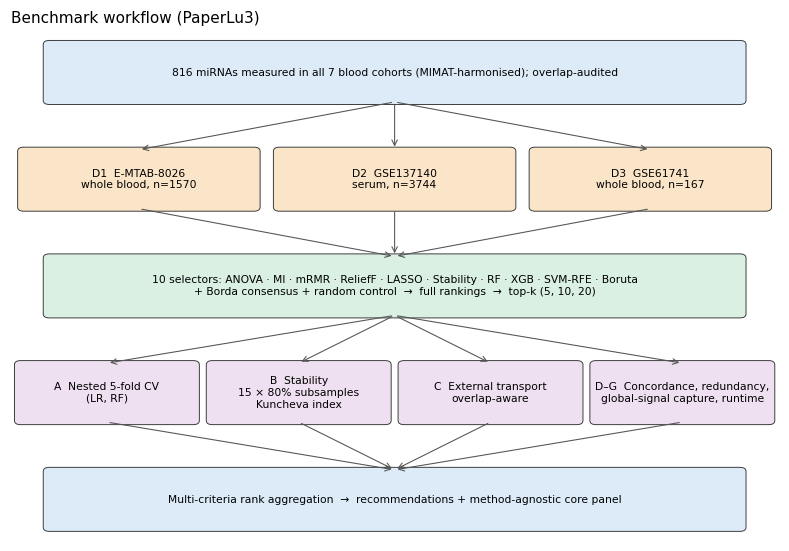

In [3]:
fig, ax = plt.subplots(figsize=(9, 6))
B, O, G, Pk = "#DCEBF7", "#FBE5C8", "#D9F0E3", "#EEE0F0"
draw_flow(ax, [
    [("816 miRNAs measured in all 7 blood cohorts (MIMAT-harmonised); overlap-audited", B)],
    [("D1  E-MTAB-8026\nwhole blood, n=1570", O), ("D2  GSE137140\nserum, n=3744", O), ("D3  GSE61741\nwhole blood, n=167", O)],
    [("10 selectors: ANOVA · MI · mRMR · ReliefF · LASSO · Stability · RF · XGB · SVM-RFE · Boruta\n+ Borda consensus + random control  →  full rankings  →  top-k (5, 10, 20)", G)],
    [("A  Nested 5-fold CV\n(LR, RF)", Pk), ("B  Stability\n15 × 80% subsamples\nKuncheva index", Pk), ("C  External transport\noverlap-aware", Pk), ("D–G  Concordance, redundancy,\nglobal-signal capture, runtime", Pk)],
    [("Multi-criteria rank aggregation  →  recommendations + method-agnostic core panel", B)],
], title="Benchmark workflow (PaperLu3)")
savefig(fig, "Fig1_benchmark_design")

## 2. Rankings: full data, CV folds and stability subsamples

In [4]:
def run_all_methods(X, y, rs):
    out, tt = {}, {}
    for m, fn in METHODS.items():
        t = time.time(); out[m] = np.asarray(fn(X, y, rs)); tt[m] = time.time() - t
    t = time.time(); out["Borda"] = borda([out[m] for m in MNAMES], X.shape[1]); tt["Borda"] = time.time() - t + sum(tt.values())
    return out, tt

# Rankings are the expensive step (~1 h on 2 CPU cores). They are cached in cache/ so that the notebook can be
# re-run quickly; delete the cache folder to recompute everything from scratch.
import pickle
os.makedirs("cache", exist_ok=True)
RANK_FULL, TIME_FULL, RANK_FOLD, RANK_SUB, FOLDS = {}, {}, {}, {}, {}
for d, c in DISC.items():
    X, y = data[c]; Xv = X[U].values
    skf = StratifiedKFold(5, shuffle=True, random_state=RS)
    FOLDS[d] = list(skf.split(Xv, y))
    cf = f"cache/rankings_{d}.pkl"
    if os.path.exists(cf):
        cache = pickle.load(open(cf, "rb"))
    else:
        cache = {}
        cache["full"], cache["time"] = run_all_methods(Xv, y, RS)
        cache["fold"] = [run_all_methods(Xv[tr], y[tr], RS + f)[0] for f, (tr, te) in enumerate(FOLDS[d])]
        rng = np.random.default_rng(RS)
        cache["sub"] = []
        for b in range(N_SUB):
            idx = np.concatenate([rng.choice(np.where(y == l)[0], int(0.8 * (y == l).sum()), replace=False) for l in (0, 1)])
            cache["sub"].append(run_all_methods(Xv[idx], y[idx], 1000 + b)[0])
        pickle.dump(cache, open(cf, "wb"))
    RANK_FULL[d], TIME_FULL[d] = cache["full"], cache["time"]
    for f in range(5):
        RANK_FOLD[(d, f)] = cache["fold"][f]
    for b in range(N_SUB):
        RANK_SUB[(d, b)] = cache["sub"][b]
    print(d, c, "rankings ready", round(time.time() - t0), "s", flush=True)

rt = pd.DataFrame(TIME_FULL).T[MNAMES + ["Borda"]]
rt.to_csv(f"{TAB}/S1_runtime_seconds_full_data.csv")
RESULTS["runtime"] = rt.round(2).to_dict()
top = []
for d in DISC:
    for m in MNAMES + ["Borda"]:
        top.append(dict(Regime=d, Method=m, Top10="; ".join(NAMES[U[i]].replace("hsa-", "") for i in RANK_FULL[d][m][:10])))
pd.DataFrame(top).to_csv(f"{TAB}/S2_top10_per_method_full_data.csv", index=False)
rt.round(1)

D1 E-MTAB-8026 rankings ready 20 s
D2 GSE137140 rankings ready 20 s
D3 GSE61741 rankings ready 20 s


,ANOVA,MutualInfo,mRMR,ReliefF,LASSO,StabilitySel,RF-Imp,XGB-Gain,SVM-RFE,Boruta,Borda
D1,0.0,3.9,0.5,0.5,2.0,1.6,9.2,69.0,1.5,17.1,105.3
D2,0.0,8.0,0.2,0.6,2.7,4.3,20.8,48.1,2.0,31.0,117.6
D3,0.0,1.1,0.0,0.0,0.1,0.2,1.2,27.2,0.4,7.0,37.2


## 3. (A) Nested cross-validated discrimination

In [5]:
def fitp(Xtr, ytr, Xte, clf):
    m = clone(make_models(RS, (ytr == 0).sum() / max(ytr.sum(), 1))[clf]).fit(Xtr, ytr)
    return m.predict_proba(Xte)[:, 1]

cv_rows = []
rng = np.random.default_rng(7)
for d, c in DISC.items():
    X, y = data[c]; Xv = X[U].values
    for clf in CLFS:
        for k in KS:
            S = {m: np.zeros(len(y)) for m in MNAMES + ["Borda"]}
            SR = np.zeros((N_RANDOM, len(y)))
            for f, (tr, te) in enumerate(FOLDS[d]):
                for m in S:
                    feats = RANK_FOLD[(d, f)][m][:k]
                    S[m][te] = fitp(Xv[tr][:, feats], y[tr], Xv[te][:, feats], clf)
                if clf == "LR":
                    for r in range(N_RANDOM):
                        feats = rng.choice(P, k, replace=False)
                        SR[r, te] = fitp(Xv[tr][:, feats], y[tr], Xv[te][:, feats], clf)
            for m in S:
                cv_rows.append(dict(Regime=d, Classifier=clf, k=k, Method=m, AUC=roc_auc_score(y, S[m]),
                                    Brier=brier_score_loss(y, S[m])))
            if clf == "LR":
                ar = [roc_auc_score(y, SR[r]) for r in range(N_RANDOM)]
                cv_rows.append(dict(Regime=d, Classifier=clf, k=k, Method="Random", AUC=np.mean(ar), AUC_sd=np.std(ar),
                                    Brier=np.mean([brier_score_loss(y, SR[r]) for r in range(N_RANDOM)])))
    print(d, "CV done", round(time.time() - t0), "s", flush=True)
CVT = pd.DataFrame(cv_rows); CVT.to_csv(f"{TAB}/Table3_nestedCV_AUC.csv", index=False)
RESULTS["cv"] = CVT.round(4).to_dict(orient="records")
CVT[(CVT.k == 10)].pivot_table(index="Method", columns=["Regime", "Classifier"], values="AUC").round(3)

D1 CV done 152 s
D2 CV done 319 s
D3 CV done 442 s


Regime           D1            D2            D3       
Classifier       LR     RF     LR     RF     LR     RF
Method                                                
ANOVA         0.850  0.919  0.994  0.995  0.865  0.882
Borda         0.896  0.937  0.999  1.000  0.891  0.900
Boruta        0.874  0.915  0.999  1.000  0.858  0.868
LASSO         0.912  0.947  0.999  1.000  0.916  0.908
MutualInfo    0.845  0.921  0.999  1.000  0.850  0.878
RF-Imp        0.893  0.942  0.999  1.000  0.858  0.884
Random        0.753    NaN  0.944    NaN  0.746    NaN
ReliefF       0.797  0.907  0.999  1.000  0.881  0.887
SVM-RFE       0.955  0.962  1.000  1.000  0.887  0.920
StabilitySel  0.915  0.949  0.999  1.000  0.892  0.891
XGB-Gain      0.903  0.953  0.999  1.000  0.871  0.871
mRMR          0.879  0.939  0.995  0.997  0.889  0.896

## 4. (B) Selection stability — Kuncheva index over 15 rankings (5 CV training folds + 10 subsamples)

In [6]:
st_rows = []
for d in DISC:
    for m in MNAMES + ["Borda"]:
        ranks = [RANK_FOLD[(d, f)][m] for f in range(5)] + [RANK_SUB[(d, b)][m] for b in range(N_SUB)]
        for k in KS:
            sets = [r[:k] for r in ranks]
            jac = np.mean([jaccard(a, b) for i, a in enumerate(sets) for b in sets[i + 1:]])
            st_rows.append(dict(Regime=d, Method=m, k=k, Kuncheva=kuncheva(sets, P), Jaccard=jac,
                                Agreement_with_full=np.mean([jaccard(s, RANK_FULL[d][m][:k]) for s in sets])))
    for k in KS:
        rs_ = [np.random.default_rng(i).choice(P, k, replace=False) for i in range(15)]
        st_rows.append(dict(Regime=d, Method="Random", k=k, Kuncheva=kuncheva(rs_, P),
                            Jaccard=np.mean([jaccard(a, b) for i, a in enumerate(rs_) for b in rs_[i + 1:]]), Agreement_with_full=np.nan))
ST = pd.DataFrame(st_rows); ST.to_csv(f"{TAB}/Table4_stability.csv", index=False)
RESULTS["stability"] = ST.round(4).to_dict(orient="records")
ST[ST.k == 10].pivot_table(index="Method", columns="Regime", values="Kuncheva").round(3)

Regime,D1,D2,D3
Method,,,
ANOVA,0.775,1.000,0.677
Borda,0.720,0.879,0.567
Boruta,0.889,0.866,0.670
LASSO,0.754,0.834,0.552
MutualInfo,0.680,0.897,0.533
RF-Imp,0.761,0.719,0.658
Random,0.003,0.003,0.003
ReliefF,0.727,0.932,0.641
SVM-RFE,0.441,0.796,0.277


## 5. (C) External transportability (overlap-aware)
Model = top-k of the full-data ranking + fixed classifier, trained on the whole discovery cohort, applied unchanged.
Test samples sharing a participant/array with the discovery cohort are removed; cohorts with < 10 remaining cases are
reported but excluded from summaries.

In [7]:
ex_rows = []
rng = np.random.default_rng(11)
for d, c in DISC.items():
    X, y = data[c]; Xv = X[U].values
    tests = {}
    for j in COHORT_ORDER:
        if j == c:
            continue
        Xj, yj = data[j]
        keep = ~Xj.index.isin(list(overlap_ids(clusters, j, [c])))
        yk = yj[keep]
        if min(yk.sum(), (yk == 0).sum()) < 3:
            continue
        fam = "within-family" if COHORTS[j]["family"] == COHORTS[c]["family"] else "cross-family"
        tests[j] = (Xj[U].values[keep], yk, fam)
    for clf in CLFS:
        for k in KS:
            for m in MNAMES + ["Borda"]:
                feats = RANK_FULL[d][m][:k]
                mdl = clone(make_models(RS, (y == 0).sum() / max(y.sum(), 1))[clf]).fit(Xv[:, feats], y)
                for j, (Xjk, yk, fam) in tests.items():
                    p = mdl.predict_proba(Xjk[:, feats])[:, 1]
                    ex_rows.append(dict(Regime=d, Test=j, Relation=fam, N=len(yk), Cases=int(yk.sum()),
                                        Classifier=clf, k=k, Method=m, AUC=roc_auc_score(yk, p), Brier=brier_score_loss(yk, p)))
            if clf == "LR":
                ar = {j: [] for j in tests}
                for r in range(N_RANDOM):
                    feats = rng.choice(P, k, replace=False)
                    mdl = clone(make_models(RS)[clf]).fit(Xv[:, feats], y)
                    for j, (Xjk, yk, fam) in tests.items():
                        ar[j].append(roc_auc_score(yk, mdl.predict_proba(Xjk[:, feats])[:, 1]))
                for j, (Xjk, yk, fam) in tests.items():
                    ex_rows.append(dict(Regime=d, Test=j, Relation=fam, N=len(yk), Cases=int(yk.sum()),
                                        Classifier=clf, k=k, Method="Random", AUC=np.mean(ar[j]), Brier=np.nan))
    print(d, "external done", round(time.time() - t0), "s", flush=True)
EX = pd.DataFrame(ex_rows); EX.to_csv(f"{TAB}/S3_external_all.csv", index=False)
EXs = EX[EX.Cases >= 10]
EXsum = EXs.groupby(["Regime", "Relation", "Classifier", "k", "Method"]).AUC.agg(["mean", "min", "max", "count"]).reset_index()
EXsum.to_csv(f"{TAB}/Table5_external_summary.csv", index=False)
RESULTS["external_summary"] = EXsum.round(4).to_dict(orient="records")
RESULTS["external_cohorts_used"] = EXs.groupby(["Regime", "Relation"]).Test.unique().apply(list).reset_index().to_dict(orient="records")
EXsum[(EXsum.k == 10) & (EXsum.Classifier == "LR")].pivot_table(index="Method", columns=["Regime", "Relation"], values="mean").round(3)

D1 external done 484 s
D2 external done 527 s
D3 external done 554 s


Regime,D1,D2,D3
Relation,cross-family,cross-family,cross-family
Method,,,
ANOVA,0.615,0.455,0.179
Borda,0.602,0.560,0.322
Boruta,0.417,0.582,0.211
LASSO,0.521,0.576,0.197
MutualInfo,0.473,0.562,0.486
RF-Imp,0.605,0.577,0.360
Random,0.503,0.492,0.400
ReliefF,0.412,0.550,0.277


## 6. (D–F) Biological concordance, redundancy and global-signal capture (top-20 of full-data ranking)
* **Replication rate**: fraction of selected miRNAs with FDR < 0.05 and the same direction in the *independent* core cohorts
  not used for discovery (E-MTAB-8026, GSE137140, GSE61741).
* **Tissue agreement**: same direction as TCGA tumour-vs-normal (FDR < 0.05).
* **Redundancy**: mean |Pearson r| among selected miRNAs in the discovery cohort.
* **Global-signal capture**: mean |r| between selected miRNAs and the per-sample mean z-score.

In [8]:
core = ["E-MTAB-8026", "GSE137140", "GSE61741"]
bio_rows = []
KB = 20
for d, c in DISC.items():
    X, y = data[c]; Xv = X[U].values
    A0 = FULL_ANOVA[c]
    others = [o for o in core if o != c]
    for m in MNAMES + ["Borda", "Random"]:
        if m == "Random":
            sets = [np.random.default_rng(i).choice(P, KB, replace=False) for i in range(N_RANDOM)]
        else:
            sets = [RANK_FULL[d][m][:KB]]
        rr, tt_, red, glob, sig_disc = [], [], [], [], []
        for s in sets:
            feats = [U[i] for i in s]
            sd = np.sign(A0.loc[feats, "hedges_g"])
            sig_disc.append((A0.loc[feats, "FDR"] < 0.05).mean())
            rep = np.mean([((FULL_ANOVA[o].loc[feats, "FDR"] < 0.05) & (np.sign(FULL_ANOVA[o].loc[feats, "hedges_g"]) == sd)).mean()
                           for o in others])
            rr.append(rep)
            tf = [f for f in feats if f in TC.index]
            tt_.append(((TC.loc[tf, "FDR"] < 0.05) & (np.sign(TC.loc[tf, "hedges_g"]) == sd.loc[tf])).mean())
            C = np.corrcoef(Xv[:, s].T); red.append(np.abs(C[np.triu_indices(KB, 1)]).mean())
            glob.append(np.mean([abs(np.corrcoef(Xv[:, i], ROWMEAN[c])[0, 1]) for i in s]))
        bio_rows.append(dict(Regime=d, Method=m, Discovery_FDR_rate=np.mean(sig_disc), Replication_rate=np.mean(rr),
                             Tissue_agreement=np.mean(tt_), Redundancy=np.mean(red), Global_capture=np.mean(glob)))
BIO = pd.DataFrame(bio_rows); BIO.to_csv(f"{TAB}/Table6_biology_redundancy_global.csv", index=False)
RESULTS["bio"] = BIO.round(4).to_dict(orient="records")
BIO.pivot_table(index="Method", columns="Regime", values=["Replication_rate", "Redundancy", "Global_capture"]).round(3)

Global_capture               Redundancy                \
Regime                   D1     D2     D3         D1     D2     D3   
Method                                                               
ANOVA                 0.526  0.744  0.098      0.470  0.729  0.322   
Borda                 0.529  0.681  0.125      0.475  0.634  0.254   
Boruta                0.521  0.725  0.089      0.619  0.702  0.272   
LASSO                 0.561  0.641  0.113      0.494  0.559  0.228   
MutualInfo            0.615  0.738  0.102      0.612  0.721  0.286   
RF-Imp                0.551  0.731  0.095      0.599  0.704  0.305   
Random                0.705  0.520  0.136      0.658  0.288  0.124   
ReliefF               0.563  0.606  0.085      0.560  0.576  0.197   
SVM-RFE               0.636  0.624  0.105      0.579  0.518  0.114   
StabilitySel          0.509  0.632  0.069      0.452  0.542  0.256   
XGB-Gain              0.549  0.560  0.105      0.498  0.442  0.227   
mRMR                  0.488  0.739  0.108      0.394  0.723  0.220   

             Replication_rate                
Regime                     D1     D2     D3  
Method                                       
ANOVA                   0.400  0.550  0.475  
Borda                   0.425  0.375  0.550  
Boruta                  0.225  0.500  0.500  
LASSO                   0.425  0.475  0.475  
MutualInfo              0.325  0.450  0.525  
RF-Imp                  0.325  0.450  0.550  
Random                  0.504  0.445  0.442  
ReliefF                 0.250  0.325  0.725  
SVM-RFE                 0.325  0.425  0.575  
StabilitySel            0.425  0.450  0.550  
XGB-Gain                0.400  0.375  0.475  
mRMR                    0.400  0.525  0.550

## 7. Figures: accuracy–stability–transport landscape

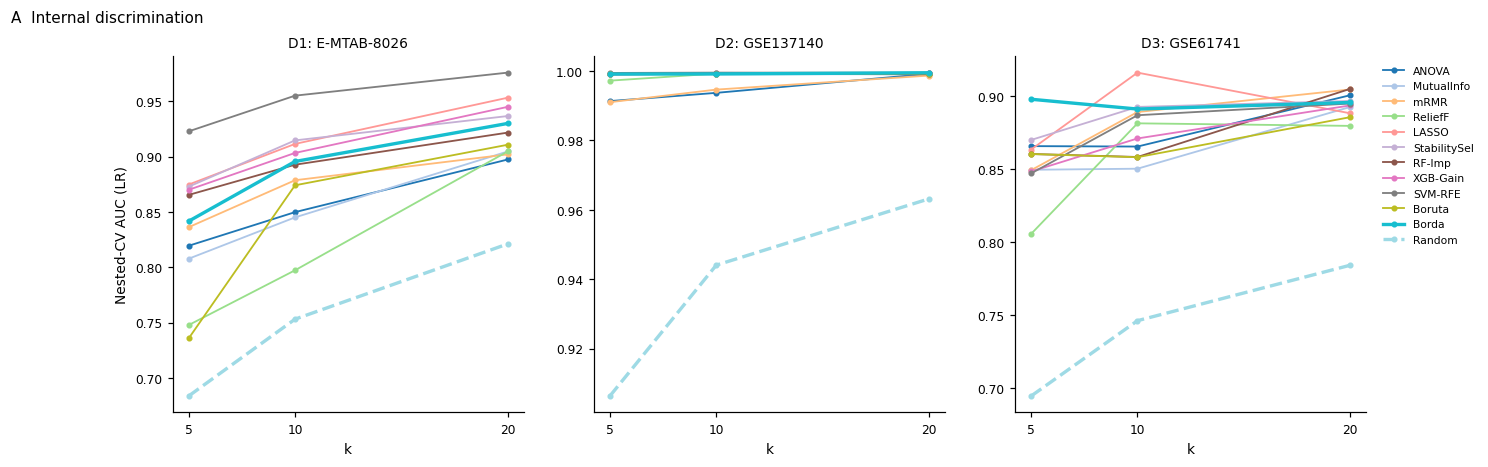

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=False)
for ax, d in zip(axes, DISC):
    for m in ALL_M:
        q = CVT[(CVT.Regime == d) & (CVT.Classifier == "LR") & (CVT.Method == m)]
        ax.plot(q.k, q.AUC, "o-", ms=3, lw=1.2 if m not in ("Borda", "Random") else 2.2,
                ls="--" if m == "Random" else "-", color=MCOL[m], label=m)
    ax.set_xticks(KS); ax.set_xlabel("k"); ax.set_title(f"{d}: {DISC[d]}", fontsize=9)
axes[0].set_ylabel("Nested-CV AUC (LR)")
axes[-1].legend(frameon=False, fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("A  Internal discrimination", x=0.02, ha="left", fontsize=10)
savefig(fig, "Fig2_nestedCV")

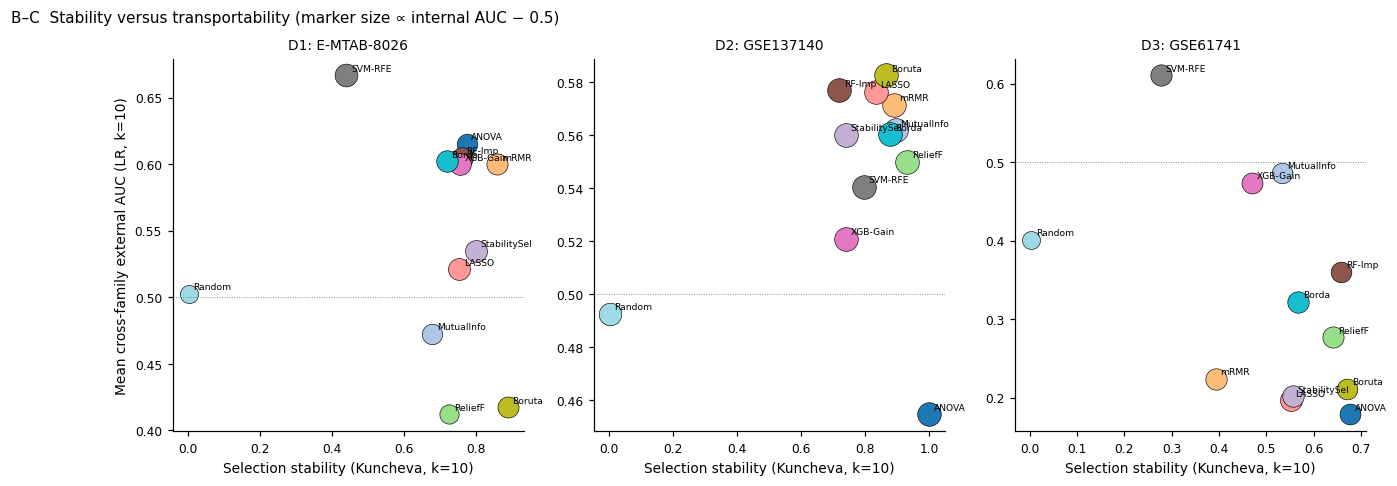

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, d in zip(axes, DISC):
    q = ST[(ST.Regime == d) & (ST.k == 10)].set_index("Method")
    cvq = CVT[(CVT.Regime == d) & (CVT.Classifier == "LR") & (CVT.k == 10)].set_index("Method")
    exq = EXsum[(EXsum.Regime == d) & (EXsum.Classifier == "LR") & (EXsum.k == 10) & (EXsum.Relation == "cross-family")].set_index("Method")
    for m in ALL_M:
        if m not in exq.index:
            continue
        ax.scatter(q.loc[m, "Kuncheva"], exq.loc[m, "mean"], s=40 + 400 * max(cvq.loc[m, "AUC"] - 0.5, 0),
                   color=MCOL[m], edgecolor="k", lw=0.4)
        ax.annotate(m, (q.loc[m, "Kuncheva"], exq.loc[m, "mean"]), fontsize=6, xytext=(3, 3), textcoords="offset points")
    ax.axhline(0.5, c="grey", lw=0.6, ls=":")
    ax.set_xlabel("Selection stability (Kuncheva, k=10)"); ax.set_title(f"{d}: {DISC[d]}", fontsize=9)
axes[0].set_ylabel("Mean cross-family external AUC (LR, k=10)")
fig.suptitle("B–C  Stability versus transportability (marker size ∝ internal AUC − 0.5)", x=0.02, ha="left", fontsize=10)
savefig(fig, "Fig3_stability_vs_transport")

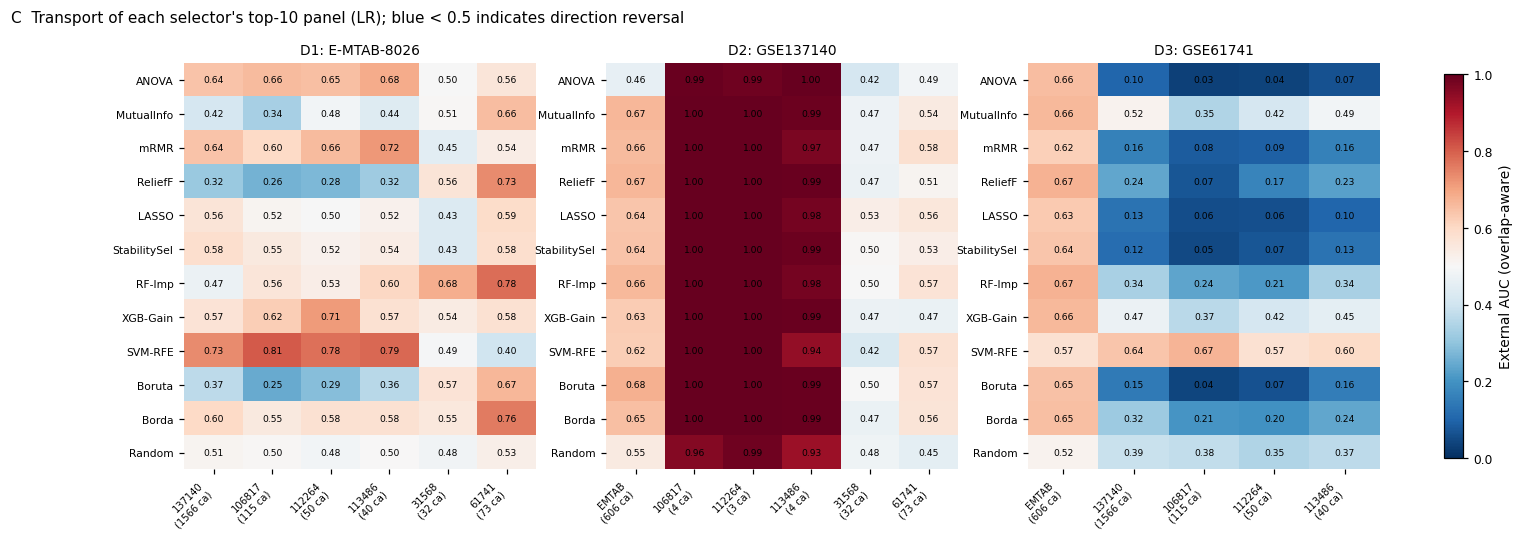

In [11]:
# External heatmap: method × test cohort (LR, k=10) for each regime
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, d in zip(axes, DISC):
    q = EX[(EX.Regime == d) & (EX.Classifier == "LR") & (EX.k == 10)]
    H = q.pivot_table(index="Method", columns="Test", values="AUC").reindex(ALL_M)
    H = H[[c for c in COHORT_ORDER if c in H.columns]]
    cases = q.groupby("Test").Cases.first()
    im = ax.imshow(H.values, cmap="RdBu_r", vmin=0, vmax=1, aspect="auto")
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            ax.text(j, i, f"{H.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
    ax.set_yticks(range(len(ALL_M))); ax.set_yticklabels(ALL_M, fontsize=7)
    ax.set_xticks(range(H.shape[1]))
    ax.set_xticklabels([f"{SHORT[c]}\n({cases[c]} ca)" for c in H.columns], fontsize=6.5, rotation=45, ha="right")
    ax.set_title(f"{d}: {DISC[d]}", fontsize=9); ax.spines[:].set_visible(False)
plt.colorbar(im, ax=axes, fraction=0.015, label="External AUC (overlap-aware)")
fig.suptitle("C  Transport of each selector's top-10 panel (LR); blue < 0.5 indicates direction reversal", x=0.02, ha="left", fontsize=10)
savefig(fig, "Fig4_external_heatmap")

## 8. Agreement between selectors and the method-agnostic core (D1, k = 20)

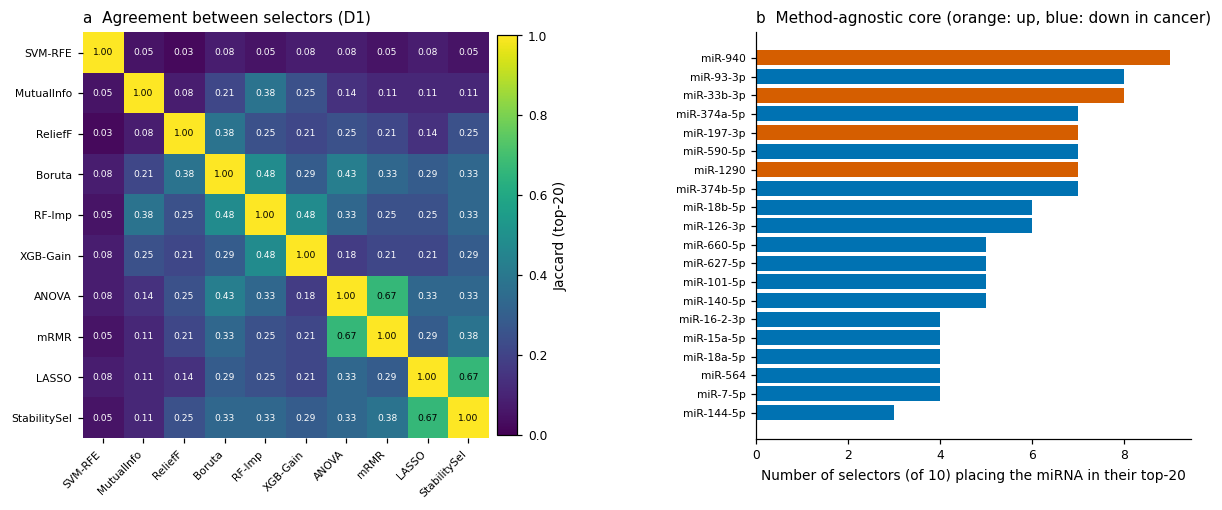

In [12]:
for d in DISC:
    sets = {m: set(RANK_FULL[d][m][:20]) for m in MNAMES}
    J = pd.DataFrame([[jaccard(sets[a], sets[b]) for b in MNAMES] for a in MNAMES], index=MNAMES, columns=MNAMES)
    J.to_csv(f"{TAB}/S4_jaccard_between_methods_{d}.csv")
    cnt = pd.Series(0, index=range(P))
    for m in MNAMES:
        cnt[list(sets[m])] += 1
    freq = cnt[cnt > 0].sort_values(ascending=False)
    fr = pd.DataFrame({"feature": [U[i] for i in freq.index], "miRNA": [NAMES[U[i]] for i in freq.index], "n_methods": freq.values})
    A0 = FULL_ANOVA[DISC[d]]
    fr["hedges_g"] = A0.loc[fr.feature, "hedges_g"].values; fr["FDR"] = A0.loc[fr.feature, "FDR"].values
    for o in core:
        if o != DISC[d]:
            fr[f"g_{SHORT[o]}"] = FULL_ANOVA[o].loc[fr.feature, "hedges_g"].values
    fr["g_TCGA"] = TC.reindex(fr.feature).hedges_g.values
    fr.to_csv(f"{TAB}/S5_selection_frequency_{d}.csv", index=False)
    if d == "D1":
        J1, FR1 = J, fr

Z = linkage(1 - J1.values[np.triu_indices(len(MNAMES), 1)], "average")
order = leaves_list(Z)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw=dict(width_ratios=[1, 1.0], wspace=0.55))
ax = axes[0]
Jo = J1.iloc[order, order]
im = ax.imshow(Jo.values, cmap="viridis", vmin=0, vmax=1)
for i in range(len(order)):
    for j in range(len(order)):
        ax.text(j, i, f"{Jo.values[i, j]:.2f}", ha="center", va="center", fontsize=6, color="w" if Jo.values[i, j] < 0.5 else "k")
ax.set_xticks(range(len(order))); ax.set_xticklabels(Jo.columns, rotation=45, ha="right", fontsize=7)
ax.set_yticks(range(len(order))); ax.set_yticklabels(Jo.index, fontsize=7)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02, label="Jaccard (top-20)")
ax.set_title("a  Agreement between selectors (D1)", loc="left"); ax.spines[:].set_visible(False)
ax = axes[1]
f20 = FR1.head(20)
ax.barh(range(len(f20))[::-1], f20.n_methods, color=np.where(f20.hedges_g > 0, "#D55E00", "#0072B2"))
ax.set_yticks(range(len(f20))[::-1]); ax.set_yticklabels([m.replace("hsa-", "") for m in f20.miRNA], fontsize=7)
ax.set_xlabel("Number of selectors (of 10) placing the miRNA in their top-20")
ax.set_title("b  Method-agnostic core (orange: up, blue: down in cancer)", loc="left")
savefig(fig, "Fig5_selector_agreement_core")
RESULTS["core_D1"] = FR1.head(20).round(3).to_dict(orient="records")
RESULTS["jaccard_D1_mean_offdiag"] = float(J1.values[np.triu_indices(len(MNAMES), 1)].mean())

## 9. (G) Multi-criteria ranking
Criteria per regime (k = 10, LR unless stated): internal AUC, Kuncheva stability, mean cross-family external AUC, mean
within-family external AUC (where available), replication rate, tissue agreement, low redundancy, low global-signal capture,
low runtime. Ranks (1 = best) are averaged within regime and then across regimes.

In [13]:
crit_rows = []
for d in DISC:
    for m in MNAMES + ["Borda"]:
        r = dict(Regime=d, Method=m)
        r["Internal_AUC"] = CVT[(CVT.Regime == d) & (CVT.Classifier == "LR") & (CVT.k == 10) & (CVT.Method == m)].AUC.iloc[0]
        r["Stability"] = ST[(ST.Regime == d) & (ST.k == 10) & (ST.Method == m)].Kuncheva.iloc[0]
        for rel in ["cross-family", "within-family"]:
            q = EXsum[(EXsum.Regime == d) & (EXsum.Relation == rel) & (EXsum.Classifier == "LR") & (EXsum.k == 10) & (EXsum.Method == m)]
            r[f"Ext_{rel}"] = q["mean"].iloc[0] if len(q) else np.nan
        b = BIO[(BIO.Regime == d) & (BIO.Method == m)].iloc[0]
        r.update(Replication=b.Replication_rate, Tissue=b.Tissue_agreement, Redundancy=b.Redundancy, Global=b.Global_capture)
        r["Runtime_s"] = TIME_FULL[d][m]
        crit_rows.append(r)
CR = pd.DataFrame(crit_rows)
higher = ["Internal_AUC", "Stability", "Ext_cross-family", "Ext_within-family", "Replication", "Tissue"]
# within-family transport is only estimable where >= 10 non-overlapping cases remain; drop the criterion if never estimable
higher = [h for h in higher if CR[h].notna().any()]
lower = ["Redundancy", "Global", "Runtime_s"]
RK = CR[["Regime", "Method"]].copy()
for col in higher + lower:
    RK[col] = CR.groupby("Regime")[col].rank(ascending=col in lower, method="average")
RK["Mean_rank"] = RK[higher + lower].mean(axis=1)
overall = RK.groupby("Method")[higher + lower + ["Mean_rank"]].mean().sort_values("Mean_rank")
CR.to_csv(f"{TAB}/Table7_criteria_values.csv", index=False)
overall.to_csv(f"{TAB}/Table8_multicriteria_ranking.csv")
RESULTS["overall_rank"] = overall.round(3).reset_index().to_dict(orient="records")
RESULTS["criteria"] = CR.round(4).to_dict(orient="records")
overall.round(2)

,Internal_AUC,Stability,Ext_cross-family,Replication,Tissue,Redundancy,Global,Runtime_s,Mean_rank
Method,,,,,,,,,
StabilitySel,2.33,6.00,7.67,4.00,5.50,4.00,2.33,5.33,4.65
mRMR,7.00,5.33,5.33,3.83,6.00,4.67,6.67,2.33,5.15
SVM-RFE,2.33,10.00,3.67,5.83,6.33,3.67,7.00,4.67,5.44
LASSO,2.00,7.00,7.00,5.67,5.33,4.67,7.67,5.00,5.54
ReliefF,7.00,4.67,8.33,7.33,7.50,4.67,4.33,2.67,5.81
ANOVA,9.33,2.00,8.00,5.33,6.67,8.33,6.67,1.00,5.92
Borda,5.00,6.33,5.00,5.17,4.17,5.33,7.33,11.00,6.17
Boruta,8.67,3.00,6.33,7.33,3.83,8.67,4.33,9.00,6.40
XGB-Gain,5.67,8.33,6.33,8.17,5.17,3.67,5.00,10.00,6.54


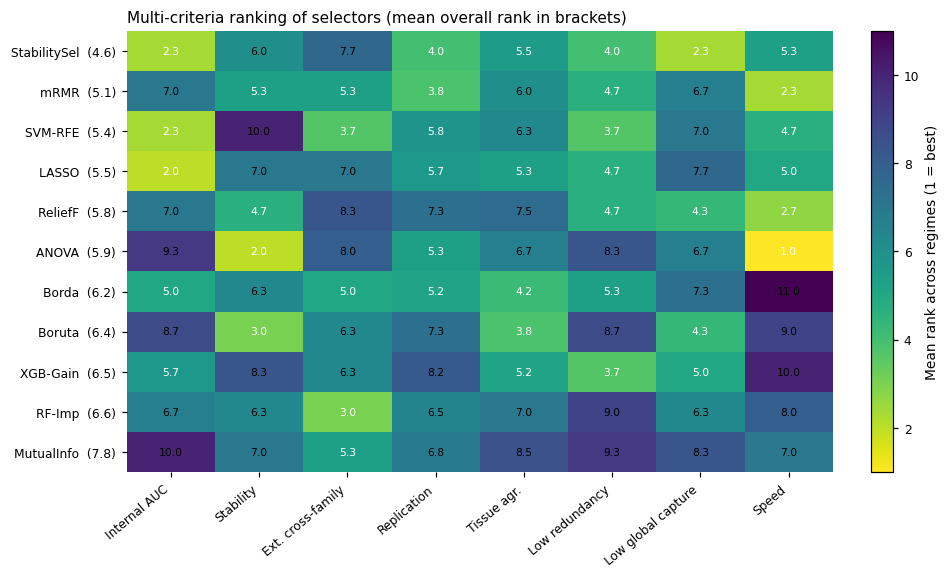

In [14]:
fig, ax = plt.subplots(figsize=(9, 5.2))
H = overall[higher + lower]
im = ax.imshow(H.values, cmap="viridis_r", vmin=1, vmax=len(MNAMES) + 1, aspect="auto")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        ax.text(j, i, "–" if not np.isfinite(v) else f"{v:.1f}", ha="center", va="center", fontsize=7,
                color="w" if np.isfinite(v) and v < 6 else "k")
ax.set_yticks(range(len(H))); ax.set_yticklabels([f"{m}  ({overall.Mean_rank[m]:.1f})" for m in H.index])
LAB = {"Internal_AUC": "Internal AUC", "Stability": "Stability", "Ext_cross-family": "Ext. cross-family",
       "Ext_within-family": "Ext. within-family", "Replication": "Replication", "Tissue": "Tissue agr.",
       "Redundancy": "Low redundancy", "Global": "Low global capture", "Runtime_s": "Speed"}
labels = [LAB[c] for c in higher + lower]
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=40, ha="right")
plt.colorbar(im, ax=ax, fraction=0.03, label="Mean rank across regimes (1 = best)")
ax.set_title("Multi-criteria ranking of selectors (mean overall rank in brackets)", loc="left"); ax.spines[:].set_visible(False)
savefig(fig, "Fig6_multicriteria")

## 10. Sensitivity: does the downstream classifier or k change the conclusions?

In [15]:
sens = []
for clf in CLFS:
    for k in KS:
        a = CVT[(CVT.Classifier == clf) & (CVT.k == k) & (CVT.Method.isin(MNAMES + ["Borda"]))]
        e = EXsum[(EXsum.Classifier == clf) & (EXsum.k == k) & (EXsum.Relation == "cross-family") & (EXsum.Method.isin(MNAMES + ["Borda"]))]
        ra = a.groupby("Regime").apply(lambda q: q.set_index("Method").AUC.rank(ascending=False)).reset_index()
        re_ = e.groupby("Regime").apply(lambda q: q.set_index("Method")["mean"].rank(ascending=False)).reset_index()
        sens.append(dict(Classifier=clf, k=k,
                         internal_spread=a.groupby("Regime").AUC.agg(lambda v: v.max() - v.min()).mean(),
                         external_spread=e.groupby("Regime")["mean"].agg(lambda v: v.max() - v.min()).mean(),
                         best_internal=a.loc[a.groupby("Regime").AUC.idxmax()].Method.tolist(),
                         best_external=e.loc[e.groupby("Regime")["mean"].idxmax()].Method.tolist()))
SENS = pd.DataFrame(sens); SENS.to_csv(f"{TAB}/S6_sensitivity_classifier_k.csv", index=False)
RESULTS["sensitivity"] = SENS.to_dict(orient="records")
# Correlation between internal AUC and external transport across method × regime (LR, k=10)
cc = CR.dropna(subset=["Ext_cross-family"])
rho = stats.spearmanr(cc.Internal_AUC, cc["Ext_cross-family"])
rho2 = stats.spearmanr(cc.Stability, cc["Ext_cross-family"])
rho3 = stats.spearmanr(cc.Global, cc["Ext_cross-family"])
RESULTS["assoc"] = dict(internal_vs_external=[rho.correlation, rho.pvalue], stability_vs_external=[rho2.correlation, rho2.pvalue],
                        global_vs_external=[rho3.correlation, rho3.pvalue])
print(RESULTS["assoc"]); SENS

{'internal_vs_external': [np.float64(0.3372326203208556), np.float64(0.05495885087422207)], 'stability_vs_external': [np.float64(0.31918449197860965), np.float64(0.0702079634094576)], 'global_vs_external': [np.float64(0.5056818181818182), np.float64(0.002681535121104865)]}


,Classifier,k,internal_spread,external_spread,best_internal,best_external
0,LR,5,0.095950,0.269393,"[SVM-RFE, SVM-RFE, Borda]","[RF-Imp, SVM-RFE, ReliefF]"
1,LR,10,0.076511,0.271356,"[SVM-RFE, SVM-RFE, LASSO]","[SVM-RFE, Boruta, SVM-RFE]"
2,LR,20,0.034922,0.218894,"[SVM-RFE, SVM-RFE, RF-Imp]","[SVM-RFE, StabilitySel, SVM-RFE]"
3,RF,5,0.069307,0.276038,"[SVM-RFE, Boruta, Borda]","[RF-Imp, MutualInfo, SVM-RFE]"
4,RF,10,0.037113,0.334807,"[SVM-RFE, XGB-Gain, SVM-RFE]","[XGB-Gain, Borda, SVM-RFE]"
5,RF,20,0.025563,0.231388,"[XGB-Gain, XGB-Gain, SVM-RFE]","[XGB-Gain, ReliefF, SVM-RFE]"


## 11. Recommended consensus panel (D1 Borda top-10) — characterisation and external performance

In [16]:
feats = [U[i] for i in RANK_FULL["D1"]["Borda"][:10]]
X, y = data["E-MTAB-8026"]
pan = pd.DataFrame({"feature": feats, "miRNA": [NAMES[f] for f in feats]})
for c in COHORT_ORDER:
    pan[f"g_{SHORT[c]}"] = FULL_ANOVA[c].loc[feats, "hedges_g"].values
pan["g_TCGA"] = TC.reindex(feats).hedges_g.values
pan["n_selectors_top20_D1"] = [int(FR1.set_index("feature").n_methods.get(f, 0)) for f in feats]
pan.to_csv(f"{TAB}/Table9_consensus_panel_D1.csv", index=False)
m = clone(make_models(RS)["LR"]).fit(X[feats].values, y)
pp = []
for c in COHORT_ORDER:
    if c == "E-MTAB-8026":
        continue
    a, lo, hi = auc_delong(data[c][1], m.predict_proba(data[c][0][feats].values)[:, 1])
    pp.append(dict(Test=c, AUC=a, lo=lo, hi=hi))
PP = pd.DataFrame(pp); PP.to_csv(f"{TAB}/S7_consensus_panel_external.csv", index=False)
RESULTS["panel"] = pan.round(3).to_dict(orient="records"); RESULTS["panel_external"] = PP.round(4).to_dict(orient="records")
pan.round(2)

,feature,miRNA,g_EMTAB,g_137140,g_106817,g_112264,g_113486,g_31568,g_61741,g_TCGA,n_selectors_top20_D1
0,MIMAT0004983,hsa-miR-940,0.71,1.28,1.12,2.00,1.94,0.14,0.33,1.05,9
1,MIMAT0004811,hsa-miR-33b-3p,0.71,0.99,0.89,1.34,0.55,0.01,-0.09,0.25,8
2,MIMAT0005880,hsa-miR-1290,0.66,2.30,1.77,4.06,2.01,0.08,0.58,0.18,7
3,MIMAT0004955,hsa-miR-374b-5p,-0.60,0.88,1.00,1.64,0.99,-0.13,-0.75,-0.67,7
4,MIMAT0000431,hsa-miR-140-5p,-0.52,0.80,0.90,1.48,0.74,0.01,0.40,-0.70,5
5,MIMAT0000727,hsa-miR-374a-5p,-0.62,0.79,1.13,1.29,0.92,0.18,-0.34,-0.77,7
6,MIMAT0001412,hsa-miR-18b-5p,-0.59,0.61,0.67,0.88,0.60,-0.03,-0.18,-0.21,6
7,MIMAT0003258,hsa-miR-590-5p,-0.53,1.51,1.73,2.12,1.33,-0.16,-0.51,1.42,7
8,MIMAT0000444,hsa-miR-126-5p,-0.45,0.76,0.94,1.12,0.97,0.02,0.40,-1.35,2
9,MIMAT0004513,hsa-miR-101-5p,-0.37,0.83,0.97,1.84,1.00,0.30,-0.33,-0.73,5


In [17]:
with pd.ExcelWriter(f"{TAB}/PaperLu3_all_tables.xlsx") as xw:
    for f in sorted(os.listdir(TAB)):
        if f.endswith(".csv"):
            pd.read_csv(f"{TAB}/{f}").to_excel(xw, sheet_name=f[:31].replace(".csv", ""), index=False)
RESULTS["universe"] = P
RESULTS["runtime_min"] = round((time.time() - t0) / 60, 1)
json.dump(RESULTS, open("results_summary.json", "w"), indent=1, default=float)
print("Finished in", RESULTS["runtime_min"], "min")

Finished in 9.4 min
